# 03 — Ajuste do Modelo MMM com Erro-Padrão HAC

**Objetivo:** ajustar a regressão OLS com correção HAC (Newey-West) e interpretar os resultados.

Roteiro:
1. Carregar dados e fazer split treino / holdout
2. Ajustar o modelo
3. Inspecionar coeficientes, p-valores e IC 95% (HAC)
4. Diagnóstico: Durbin-Watson, VIF, resíduos
5. Decomposição de contribuições por canal
6. CPA implícito vs. CPA de planejamento
7. Gráfico de significância por canal

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from statsmodels.stats.stattools import durbin_watson as dw_stat

from src.model import MMMModel, DEFAULT_CHANNEL_PARAMS
from src.validation import temporal_split, compute_metrics

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["figure.dpi"] = 110
print("Módulos carregados.")

Módulos carregados.


## 1. Carregar Dados e Split

In [2]:
df = pd.read_csv("../data/MMM_Synth_Weekly_Data.csv", parse_dates=["week"])
df = df.sort_values("week").reset_index(drop=True)

df_train, df_holdout = temporal_split(df, holdout_weeks=24)

print(f"Treino  : {len(df_train)} semanas  "
      f"({df_train['week'].min().date()} → {df_train['week'].max().date()})")
print(f"Holdout : {len(df_holdout)} semanas  "
      f"({df_holdout['week'].min().date()} → {df_holdout['week'].max().date()})")

Treino  : 80 semanas  (2023-01-02 → 2024-07-08)
Holdout : 24 semanas  (2024-07-15 → 2024-12-23)


## 2. Ajustar o Modelo

In [3]:
mmm = MMMModel(channel_params=DEFAULT_CHANNEL_PARAMS, hac_lags=4)
mmm.fit(df_train)

# Métricas in-sample
m = mmm.metrics()
print("=" * 50)
print("MÉTRICAS — PERÍODO DE TREINO")
print("=" * 50)
print(f"  R²           : {m['R2']:.4f}  ({m['R2']*100:.1f}%)")
print(f"  R² ajustado  : {m['R2_adj']:.4f}  ({m['R2_adj']*100:.1f}%)")
print(f"  MAPE         : {m['MAPE_%']:.2f}%")
print(f"  RMSE         : {m['RMSE']:,.0f} assinantes/semana")

MÉTRICAS — PERÍODO DE TREINO
  R²           : 0.9488  (94.9%)
  R² ajustado  : 0.9405  (94.0%)
  MAPE         : 0.48%
  RMSE         : 437 assinantes/semana


In [4]:
# Sumário completo do statsmodels
print(mmm.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.949
Model:                            OLS   Adj. R-squared:                  0.941
Method:                 Least Squares   F-statistic:                     374.2
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           5.70e-56
Time:                        13:26:02   Log-Likelihood:                -599.95
No. Observations:                  80   AIC:                             1222.
Df Residuals:                      69   BIC:                             1248.
Df Model:                          10                                         
Covariance Type:                  HAC                                         
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const       

## 3. Coeficientes, IC 95% e p-valores (HAC)

**Por que HAC?**  
Séries temporais de marketing apresentam autocorrelação residual — o erro-padrão OLS clássico subestima essa correlação e infla a significância estatística. O estimador HAC (Newey-West) produz erros-padrão robustos a autocorrelação e heterocedasticidade.

In [5]:
coef_df = mmm.coef_table()
coef_df["significativo (5%)"] = coef_df["p_value"] < 0.05

with pd.option_context("display.float_format", "{:.4f}".format):
    display(coef_df)

,feature,coef,std_err,t_stat,p_value,ci_lower,ci_upper,significativo (5%)
0,const,-8907.2972,1896.2923,-4.6972,0.0000,-12623.9618,-5190.6326,True
1,media_paid_search_google,8523.1661,2196.7726,3.8799,0.0001,4217.5710,12828.7612,True
2,media_social_media_meta_ads,6765.2335,2241.4842,3.0182,0.0025,2372.0051,11158.4619,True
3,media_social_media_youtube_ads,7969.1492,2213.1589,3.6008,0.0003,3631.4375,12306.8609,True
4,media_affiliate_marketing,21053.1002,1386.1022,15.1887,0.0000,18336.3898,23769.8106,True
5,media_email_marketing,19645.7564,1482.8449,13.2487,0.0000,16739.4339,22552.0790,True
6,media_e-commerce_company_site,17693.2393,1628.2988,10.8661,0.0000,14501.8323,20884.6462,True
7,media_call_center,21224.8373,1189.8772,17.8378,0.0000,18892.7207,23556.9538,True
8,seasonality_index,4720.1674,426.1073,11.0774,0.0000,3885.0125,5555.3224,True
9,trend,5535.7675,737.6852,7.5042,0.0000,4089.9311,6981.6038,True


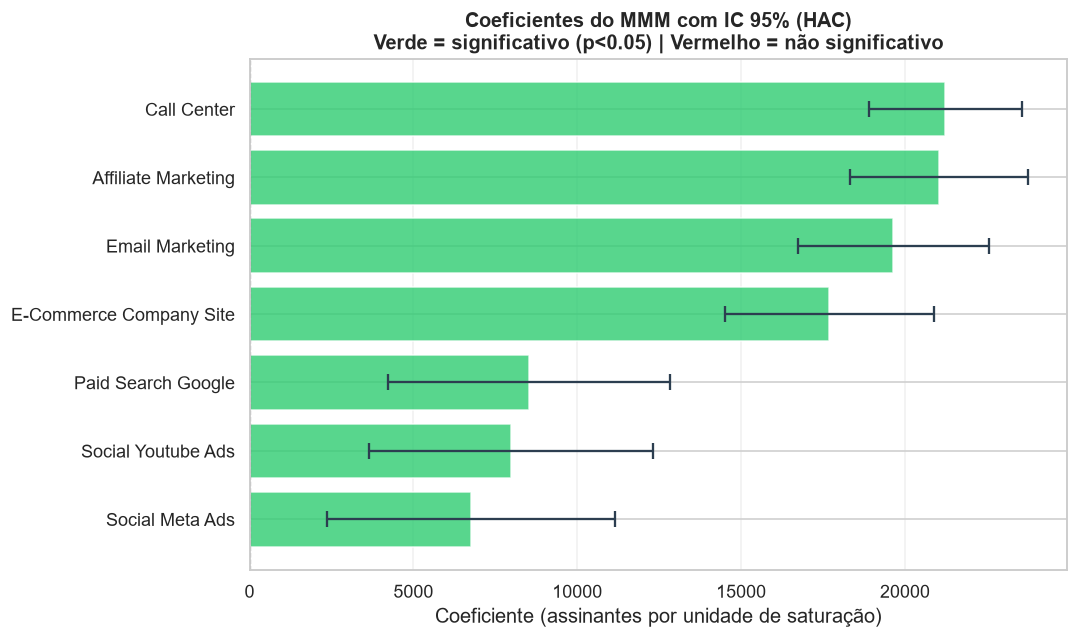

In [6]:
# Gráfico de coeficientes com IC 95%
media_coef = coef_df[coef_df["feature"].str.startswith("media_")].copy()
media_coef["canal"] = (
    media_coef["feature"]
    .str.replace("media_", "")
    .str.replace("_", " ")
    .str.title()
)
media_coef = media_coef.sort_values("coef", ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))

colors = ["#2ecc71" if p < 0.05 else "#e74c3c" for p in media_coef["p_value"]]
ax.barh(media_coef["canal"], media_coef["coef"], color=colors, alpha=0.8)

# Barras de erro
ax.errorbar(
    media_coef["coef"],
    media_coef["canal"],
    xerr=[
        media_coef["coef"] - media_coef["ci_lower"],
        media_coef["ci_upper"] - media_coef["coef"]
    ],
    fmt="none", color="#2c3e50", capsize=5, lw=1.5, capthick=1.5
)

ax.axvline(0, color="gray", lw=0.8, linestyle="--")
ax.set_xlabel("Coeficiente (assinantes por unidade de saturação)")
ax.set_title("Coeficientes do MMM com IC 95% (HAC)\n"
             "Verde = significativo (p<0.05) | Vermelho = não significativo",
             fontweight="bold")
ax.grid(True, alpha=0.3, axis="x")
plt.tight_layout()
plt.savefig("../outputs/channel_significance.png", dpi=130, bbox_inches="tight")
plt.show()

## 4. Diagnóstico: Durbin-Watson e VIF

In [7]:
# Durbin-Watson
residuals = mmm.result_.resid
dw_val    = dw_stat(residuals)
print("=" * 50)
print("DIAGNÓSTICO DE AUTOCORRELAÇÃO")
print("=" * 50)
print(f"  Durbin-Watson : {dw_val:.4f}")
print(f"  Interpretação : ", end="")
if dw_val < 1.5:
    print("Autocorrelação POSITIVA detectada → HAC é necessário ✓")
elif dw_val > 2.5:
    print("Autocorrelação NEGATIVA detectada")
else:
    print("Sem autocorrelação significativa")

DIAGNÓSTICO DE AUTOCORRELAÇÃO
  Durbin-Watson : 1.7486
  Interpretação : Sem autocorrelação significativa


In [8]:
# VIF
vif_df = mmm.vif()
print("\nVIF — Diagnóstico de Multicolinearidade")
print("  (VIF < 5 = baixa | 5-10 = moderada | > 10 = alta)")
print(vif_df.to_string(index=False))


VIF — Diagnóstico de Multicolinearidade
  (VIF < 5 = baixa | 5-10 = moderada | > 10 = alta)
                       feature      VIF
media_social_media_youtube_ads 1.304500
   media_social_media_meta_ads 1.263479
             media_call_center 1.251037
     media_affiliate_marketing 1.247781
                         trend 1.229848
             seasonality_index 1.197942
 media_e-commerce_company_site 1.174975
      media_paid_search_google 1.160913
         media_email_marketing 1.117391
               price_hike_flag 1.074489
                         const 1.000000


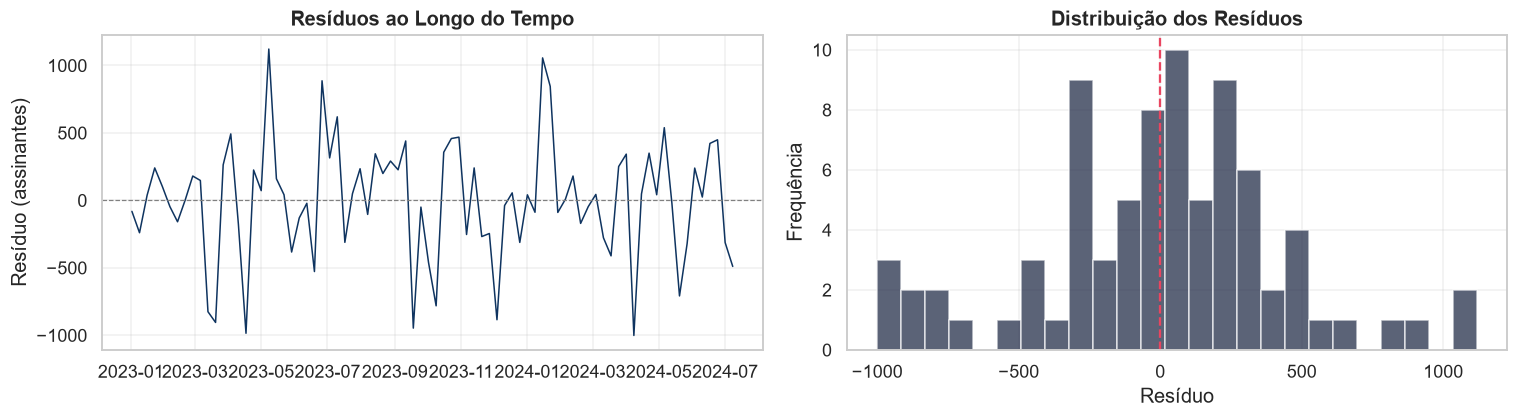

In [9]:
# Gráfico de resíduos
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Resíduos ao longo do tempo
axes[0].plot(df_train["week"], residuals, color="#0f3460", lw=1.0)
axes[0].axhline(0, color="gray", lw=0.8, linestyle="--")
axes[0].set_title("Resíduos ao Longo do Tempo", fontweight="bold")
axes[0].set_ylabel("Resíduo (assinantes)")
axes[0].grid(True, alpha=0.3)

# Distribuição dos resíduos
axes[1].hist(residuals, bins=25, color="#16213e", alpha=0.7, edgecolor="white")
axes[1].axvline(0, color="#e94560", lw=1.5, linestyle="--")
axes[1].set_title("Distribuição dos Resíduos", fontweight="bold")
axes[1].set_xlabel("Resíduo")
axes[1].set_ylabel("Frequência")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Decomposição de Contribuições por Canal

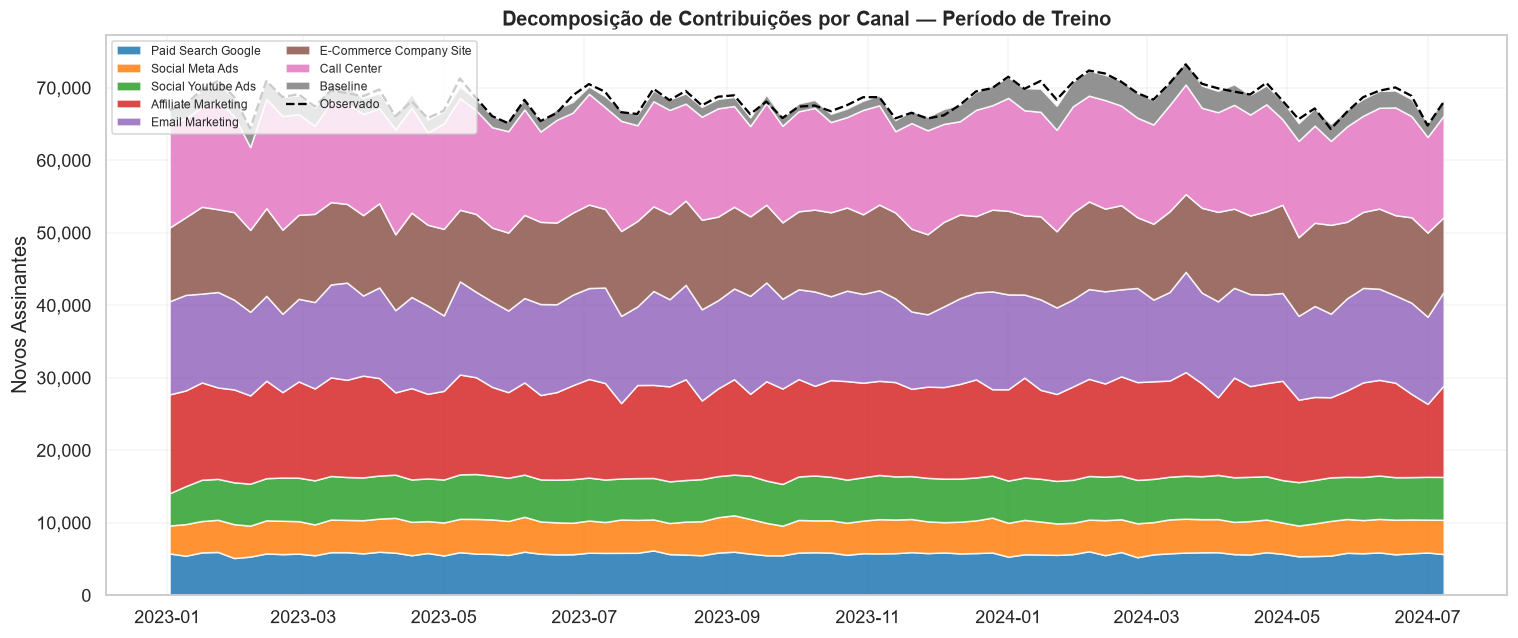


Contribuição Total — Período de Treino
  Call Center                               1,111,764 subs (20.3%)
  Affiliate Marketing                       1,017,239 subs (18.6%)
  Email Marketing                             979,343 subs (17.9%)
  E-Commerce Company Site                     902,192 subs (16.5%)
  Social Youtube Ads                          471,111 subs (8.6%)
  Paid Search Google                          458,021 subs (8.4%)
  Social Meta Ads                             362,403 subs (6.6%)
  Baseline                                    171,025 subs (3.1%)
  TOTAL                                     5,473,098


In [10]:
decomp = mmm.decompose(df_train)

# Empilhar para gráfico de área
contrib_cols = [c for c in decomp.columns if c.startswith("contrib_")]
stack_data   = decomp[contrib_cols + ["baseline"]]
channel_labels = [
    c.replace("contrib_", "").replace("_", " ").title()
    for c in stack_data.columns
]

fig, ax = plt.subplots(figsize=(14, 6))
colors  = sns.color_palette("tab10", len(stack_data.columns))

ax.stackplot(
    df_train["week"],
    stack_data.T.values,
    labels=channel_labels,
    colors=colors,
    alpha=0.85,
)

# Observado
ax.plot(df_train["week"], df_train["new_subscribers"],
        color="black", lw=1.5, linestyle="--", label="Observado", zorder=5)

ax.set_title("Decomposição de Contribuições por Canal — Período de Treino",
             fontweight="bold")
ax.set_ylabel("Novos Assinantes")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.legend(loc="upper left", fontsize=8, ncol=2)
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

# Tabela de contribuição total
contrib_total = decomp[contrib_cols + ["baseline"]].sum().sort_values(ascending=False)
total         = contrib_total.sum()
print("\nContribuição Total — Período de Treino")
for col, val in contrib_total.items():
    label = col.replace("contrib_", "").replace("_", " ").title()
    print(f"  {label:40s} {val:>10,.0f} subs ({val/total*100:.1f}%)")
print(f"  {'TOTAL':40s} {total:>10,.0f}")

## 6. CPA Implícito (MMM) vs. CPA de Planejamento

In [11]:
cpa_df = mmm.cpa_implied(df_train)
print(cpa_df.to_string(index=False))

                  canal  spend_total_R$  subs_atribuidos  CPA_implicito_R$  CPA_target_R$  ratio_imp_vs_target
        Email Marketing      4068744.34         979343.0              4.15           30.0                 0.14
            Call Center      6263245.00        1111764.0              5.63           40.0                 0.14
    Affiliate Marketing      9702372.15        1017239.0              9.54           25.0                 0.38
E-commerce Company Site     14042186.38         902192.0             15.56           70.0                 0.22
   Paid Search (Google)     32164615.51         458021.0             70.23           45.0                 1.56


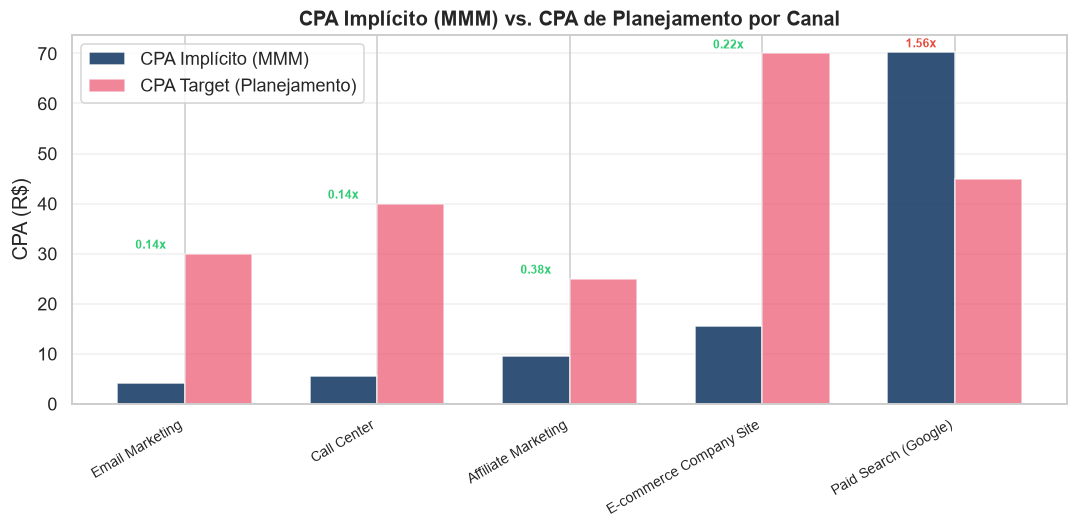

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))

x     = np.arange(len(cpa_df))
width = 0.35

bars1 = ax.bar(x - width/2, cpa_df["CPA_implicito_R$"],
               width, label="CPA Implícito (MMM)",  color="#0f3460", alpha=0.85)
bars2 = ax.bar(x + width/2, cpa_df["CPA_target_R$"],
               width, label="CPA Target (Planejamento)", color="#e94560", alpha=0.65)

ax.set_xticks(x)
ax.set_xticklabels(cpa_df["canal"], rotation=30, ha="right", fontsize=9)
ax.set_ylabel("CPA (R$)")
ax.set_title("CPA Implícito (MMM) vs. CPA de Planejamento por Canal", fontweight="bold")
ax.legend()
ax.grid(True, alpha=0.3, axis="y")

# Ratio annotation
for bar1, bar2, ratio in zip(bars1, bars2, cpa_df["ratio_imp_vs_target"]):
    color = "#2ecc71" if ratio < 1 else "#e74c3c"
    ax.text(
        bar1.get_x() + bar1.get_width() / 2,
        max(bar1.get_height(), bar2.get_height()) + 1,
        f"{ratio:.2f}x", ha="center", fontsize=8, color=color, fontweight="bold"
    )

plt.tight_layout()
plt.savefig("../outputs/cpa_implied_vs_assumed.png", dpi=130, bbox_inches="tight")
plt.show()

## 7. Ajustado vs. Observado — Treino

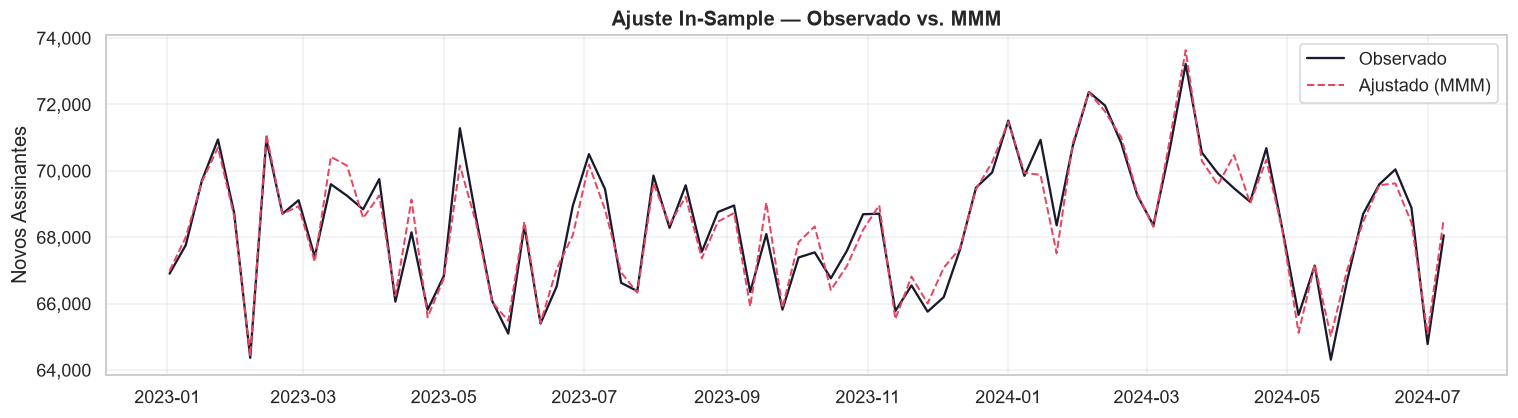


➡ Próximo notebook: 04_holdout_validation.ipynb — Validação Out-of-Sample


In [13]:
fitted = mmm.result_.fittedvalues

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df_train["week"], df_train["new_subscribers"],
        color="#1a1a2e", lw=1.5, label="Observado")
ax.plot(df_train["week"], fitted,
        color="#e94560", lw=1.3, linestyle="--", label="Ajustado (MMM)")
ax.set_title("Ajuste In-Sample — Observado vs. MMM", fontweight="bold")
ax.set_ylabel("Novos Assinantes")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\n➡ Próximo notebook: 04_holdout_validation.ipynb — Validação Out-of-Sample")